In [1]:
from AnalysisDefinitions import AnalysisUltimate as AU
import matplotlib.pyplot as plt
import numpy as np

In [2]:
folder = 'Run_1671112331.hdf5'
ult = AU(h5_folder_path='DAQ_data/'+folder,single_file = True)

biases = list(ult.biases) #what biases to analyze
biases = sorted(list(biases))
print(ult.biases)
num_pes = [6,   6,   6,   8, 9,10,10,10,10] #the number of peaks to fit, ordered by bias in increasing order
pes_dict = {biases[i+1]: num_pes[i] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is number of peaks as int
lowerlim = [37, 37, 37, 37, 37,40,40,40,45] #in mV #the lowerlims to be used, ordered by bias in increasing order
lowerlimdict = {biases[i+1]:lowerlim[i]/1000 for i in range(len(lowerlim))} #create a dictionary. Can be manual: keys are biases, data is lowerlim as float
pe_center_guesses = [45, 49, 53, 60, 65,70,75,80,84] #centers of the first pe, ordered by bias in increasing order
if pe_center_guesses:
    centers = {biases[i+1]: [pe_center_guesses[i] * peak / 1000 for peak in range(1,num_pes[i]+1)] for i in range(len(biases)-1)} #create a dictinoary. Can be manual: keys are biases, data is list of centers guesses for the multigaussian
invC = 0.011547 #inverse capacitance of pream-shaper circuit, see Noah's calibration report
invCerr = 0.000098 #error on above term

#print(biases)
uplims = {v:-1 for v in biases}
uplims[27] = 0.063
poly = {v:True for v in biases}
poly[27] = False
proms = {v:0.003  for v in biases}
proms[27] = 0.008

{np.float64(27.0): 'Acquisition_1671112353', np.float64(33.5): 'Acquisition_1671112655', np.float64(36.0): 'Acquisition_1671112971', np.float64(36.5): 'Acquisition_1671113201', np.float64(34.0): 'Acquisition_1671113441', np.float64(35.5): 'Acquisition_1671113693', np.float64(37.0): 'Acquisition_1671113952', np.float64(34.5): 'Acquisition_1671114191', np.float64(35.0): 'Acquisition_1671114382', np.float64(37.5): 'Acquisition_1671114663'}


In [3]:
#V = 37.5
#pes = 10
#c = .084
#ult.histograms[V].centers = [c*i for i in range(1,pes+1)]
#ult.histograms[V].high_peak = pes
#ult.histograms[V].numpeaks = pes
#ult.histograms[V].peak_range = (1,pes)
#ult.histograms[V].cutoff = (.045,1)
#ult.do_processhistograms(biases=[V])
#ult.histograms[V].plot_peak_histogram()

In [4]:
ult.args_processwaveforms(do_filter=True,
                        prominence=proms,
                        condition = 'GN',
                        baseline_correct=True,
                        upper_limit=uplims,
                        poly_correct=poly)


In [5]:
ult.do_processwaveforms(temperature = 243,timeit=False,biases=biases)

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': '242.5K Nitrogen/Dark', 'RunStart': '1671112331', 'User': 'Hannah'}
{'AcquisitionEnd': '12/15/2022 1:52:59 PM',
 'AcquisitionMode': 'Fast',
 'AcquisitionNote': 'Solicited',
 'AcquisitionStart': '12/15/2022 1:52:33 PM',
 'Bias(V)': np.float64(27.0),
 'Duration(S)': np.uint16(5),
 'LowerLevel': np.float64(0.5),
 'Offset': np.float64(0.0),
 'OffsetTime': np.float64(6e-06),
 'Preamp': 'CR-Z-SiPM',
 'Quota': np.float64(2000.0),
 'Range': np.float64(2.0),
 'SampleTime': np.float64(0.0001),
 'Shaper': '<0>',
 'ShaperGain1': np.uint8(1),
 'ShaperGain2': np.uint8(0),
 'SlowControlUser': 'Hannah Peltz Smalley',
 'TemperatureMean': np.float64(nan),
 'TemperatureStdDev': np.float64(-0.0),
 'TriggerMode': 'Solicited',
 'TriggerSlope': 'Rising Edge',
 'TriggerSource': 'External Trigger Source',
 'Xe(g)': np.float64(94.49032253585499)}
filename: DAQ_data/Run_1671112331.hdf5, acquisition name: Acquisition_1671112353
reading all waveforms

c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:223: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:181: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\ensom\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\_core\_methods.py:215: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

Run Meta: {'CampaignIDNumber': '', 'RunName': 'SPE', 'RunNotes': '242.5K Nitrogen/Dark', 'RunStart': '1671112331', 'User': 'Hannah'}
{'AcquisitionEnd': '12/15/2022 2:00:17 PM',
 'AcquisitionMode': 'Fast',
 'AcquisitionNote': '33.5V',
 'AcquisitionStart': '12/15/2022 1:57:35 PM',
 'Bias(V)': np.float64(33.5),
 'Duration(S)': np.uint16(20),
 'LowerLevel': np.float64(0.09),
 'Offset': np.float64(0.8),
 'OffsetTime': np.float64(6e-06),
 'Preamp': 'CR-Z-SiPM',
 'Quota': np.float64(2000.0),
 'Range': np.float64(2.0),
 'SampleTime': np.float64(0.0001),
 'Shaper': '<0>',
 'ShaperGain1': np.uint8(1),
 'ShaperGain2': np.uint8(0),
 'SlowControlUser': 'Hannah Peltz Smalley',
 'TemperatureMean': np.float64(nan),
 'TemperatureStdDev': np.float64(-0.0),
 'TriggerMode': 'Self',
 'TriggerSlope': 'Rising Edge',
 'TriggerSource': 'Input Channel 1',
 'Xe(g)': np.float64(94.49032253585499)}
filename: DAQ_data/Run_1671112331.hdf5, acquisition name: Acquisition_1671112655
using polynomial baseline correction

In [6]:
cutoffs = {}
for v in biases:
    if v <= 27:
        continue
    cutoffs[v] = (lowerlimdict[v], 1)
peak_ranges = {biases[i+1]: (1,num_pes[i]) for i in range(len(biases)-1)}

#centers = ult.guess_pe_locations(get_values=True,show_plots=True,cutoff=cutoffs)

ult.args_processhistograms(centers = centers, 
                        baseline_correct=True,
                        peaks='all',
                        cutoff=cutoffs,
                        background_linear=False,
                        peak_range=peak_ranges)

print(ult.measurementinfos)


ult.create_processhistograms()

print(ult.histograms)

{np.float64(33.5): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B93700>, np.float64(34.0): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B92DA0>, np.float64(34.5): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B920E0>, np.float64(35.0): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B933D0>, np.float64(35.5): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B93580>, np.float64(36.0): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B93460>, np.float64(36.5): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B935B0>, np.float64(37.0): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B90250>, np.float64(37.5): <MeasurementInfo.MeasurementInfo object at 0x000001AE74B919F0>, np.float64(27.0): 'not set'}
{np.float64(33.5): <ProcessHistograms.ProcessHist object at 0x000001AE74B92AD0>, np.float64(36.0): <ProcessHistograms.ProcessHist object at 0x000001AE74B939D0>, np.float64(36.5): <ProcessHistograms.ProcessHist object at 0x000001AE74

In [7]:
#print(ult.histograms[32].get_spe())

In [8]:
ult.do_processhistograms()

CENTER GUESSES TO BE USED IN FIT:  [0.045, 0.09, 0.135, 0.18, 0.225, 0.27]


c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


WARNING! Fitted sigma 0.012668268805869099 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(2.141956455132072), np.float64(1.7346419374642643), np.float64(2.133468357560977), np.float64(1.7602971902931455), np.float64(1.616257407549767)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 0.6326675293448203 +/- 0.04537513145087821
CENTER GUESSES TO BE USED IN FIT:  [0.07, 0.14, 0.21, 0.28, 0.35, 0.42, 0.49, 0.56, 0.63, 0.7]
WARNING! Fitted sigma 0.010094249394468308 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(3.2542839107663437), np.float64(3.1483321961615336), np.float64(3.245223290487897), np.float64(3.2198832420024286), np.float64(3.2566924447862364), np.float64(3.295076602689846), np.float64(3.506828510954048), np.float64(3.556090647620186), np.float64(3.8629577451833903)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.3632849249925587 +/- 0.005924331846045628
CENTER GU

c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


WARNING! Fitted sigma 0.013213160788742712 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(2.2873585965459258), np.float64(2.042905881987113), np.float64(2.2615480404031483), np.float64(1.9634269887734732), np.float64(1.579931077905571)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 0.6744193907715306 +/- 0.011754070959085022
CENTER GUESSES TO BE USED IN FIT:  [0.065, 0.13, 0.195, 0.26, 0.325, 0.39, 0.455, 0.52, 0.585]


...

WARNING! Fitted sigma 0.013459980183532715 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.012171331728273992 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.010836785148637508 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.011571731560982153 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.010439143272670294 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(3.3167913266763147), np.float64(3.2927510097970862), np.float64(3.3964854314402486), np.float64(3.396342831940006), np.float64(3.528301043048111), np.float64(4.166373757028157), np.float64(3.946124937439772), np.float64(4.566893456349985)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 1.0716738688552665 +/- 0.005228068036992965
CENTER GUESSES TO BE USED IN FIT:  [0.08, 0.16, 0.24, 0.32, 0.4, 0.48, 0.56, 0.64, 0.72, 0.8]
WARNING! Fitted sigma 0.012079969381060872 is less than

c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


WARNING! Fitted sigma 0.01304375430895811 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.012125061182353314 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.010768932673793072 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.009899600268893197 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(2.692926239138892), np.float64(2.8582973751519023), np.float64(2.9767765393643746), np.float64(3.4512300014853956), np.float64(3.8448083726527646)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 0.708485044162424 +/- 0.004299661301227185
CENTER GUESSES TO BE USED IN FIT:  [0.06, 0.12, 0.18, 0.24, 0.3, 0.36, 0.42, 0.48]


c:\Users\ensom\Documents\LabStuff\SPE-Analysis-Noah\src\ProcessHistograms.py:168: RuntimeWarning: divide by zero encountered in divide
  res = model.fit(counts, params=params, x=bin_centers, weights = 1/np.sqrt(counts), nan_policy='omit')


WARNING! Fitted sigma 0.013452673084873508 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.013191165933477859 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.012298230779848493 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.010624112438682663 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.012373587357086996 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.009814576560655812 is less than baseline sigma 0.013466043501903613!
WARNING! Fitted sigma 0.010041088062314484 is less than baseline sigma 0.013466043501903613!
sigma SNR: [np.float64(3.0379449049742573), np.float64(3.0927691770935763), np.float64(3.2439913017706554), np.float64(3.846822539054153), np.float64(3.6610788877289933), np.float64(3.7517129498912607), np.float64(4.168778060973136)]
CA at this bias voltage: mean of all amplitudes / SPE amplitude (gain slope) = 0.8445287994977084 +/- 0.00447872021

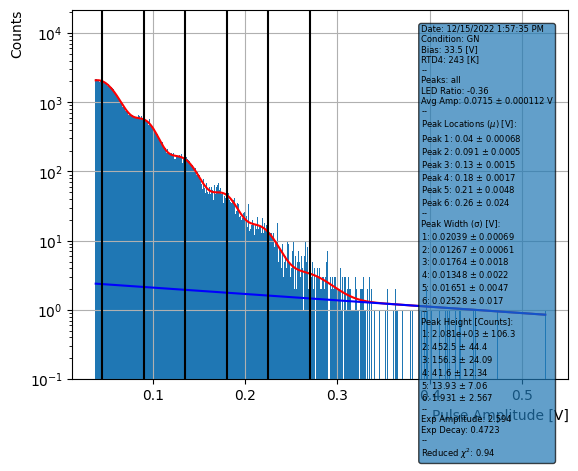

[0.045, 0.09, 0.135, 0.18, 0.225, 0.27]


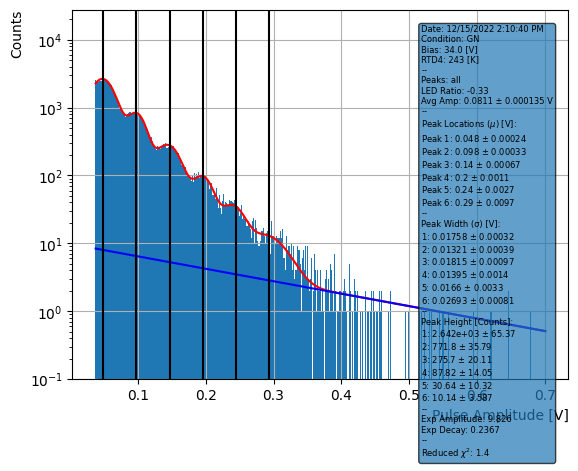

[0.049, 0.098, 0.147, 0.196, 0.245, 0.294]


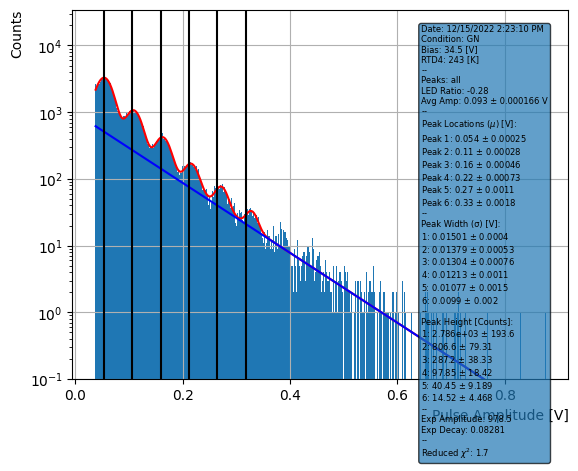

[0.053, 0.106, 0.159, 0.212, 0.265, 0.318]


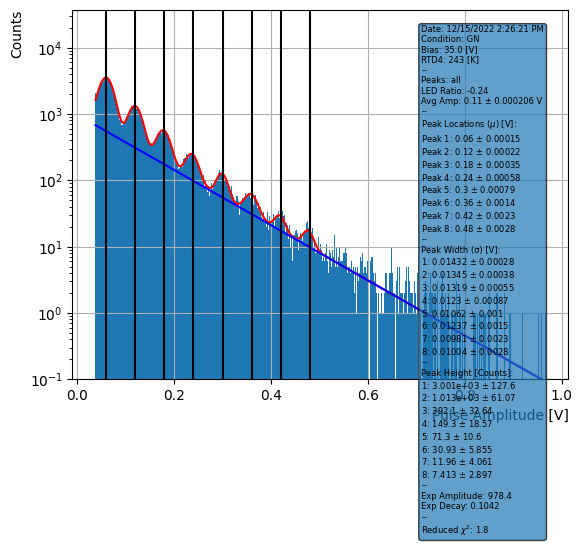

[0.06, 0.12, 0.18, 0.24, 0.3, 0.36, 0.42, 0.48]


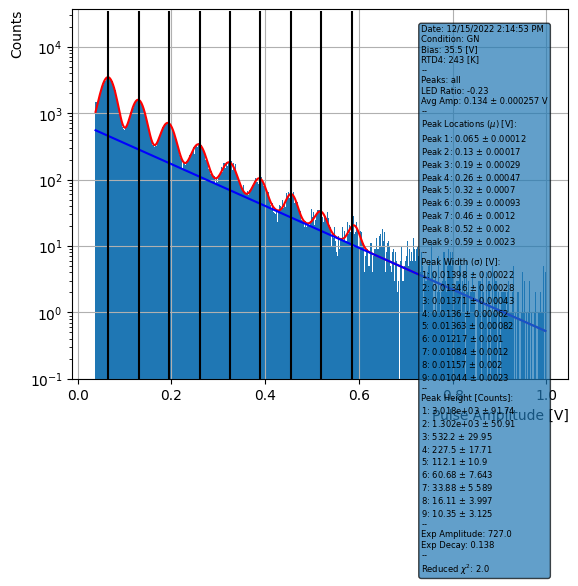

[0.065, 0.13, 0.195, 0.26, 0.325, 0.39, 0.455, 0.52, 0.585]


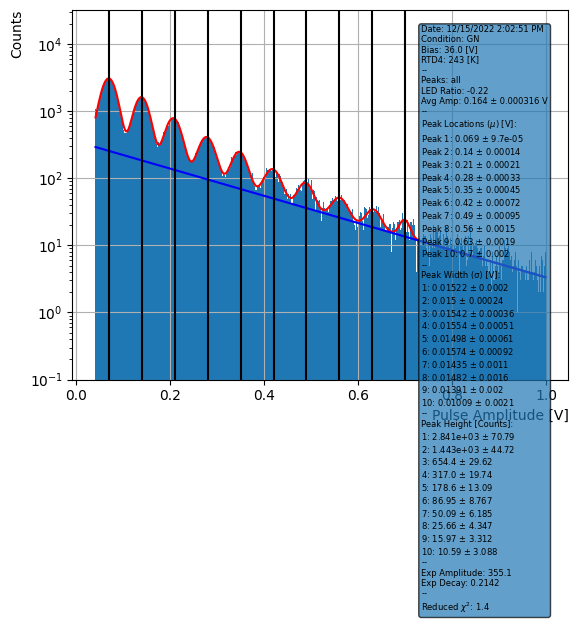

[0.07, 0.14, 0.21, 0.28, 0.35, 0.42, 0.49, 0.56, 0.63, 0.7]


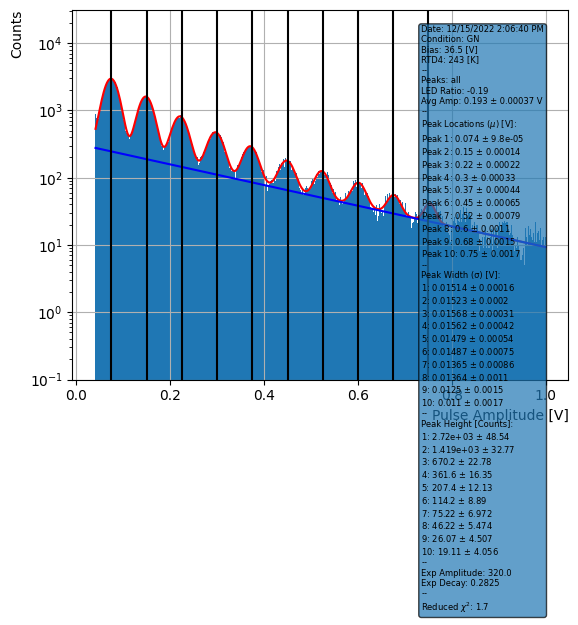

[0.075, 0.15, 0.225, 0.3, 0.375, 0.45, 0.525, 0.6, 0.675, 0.75]


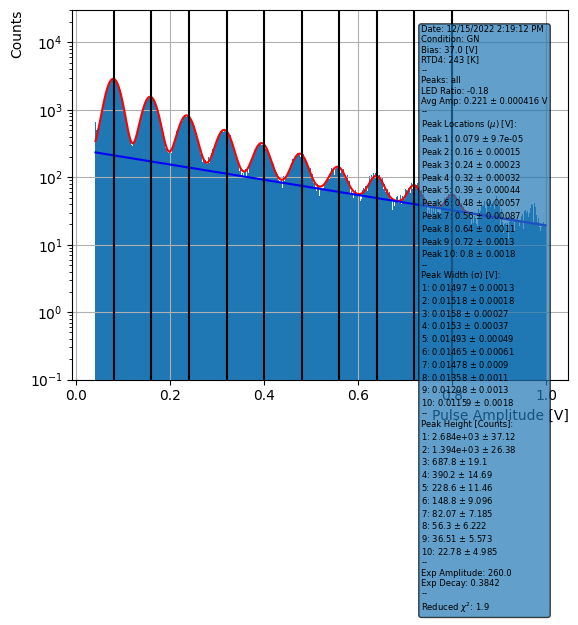

[0.08, 0.16, 0.24, 0.32, 0.4, 0.48, 0.56, 0.64, 0.72, 0.8]


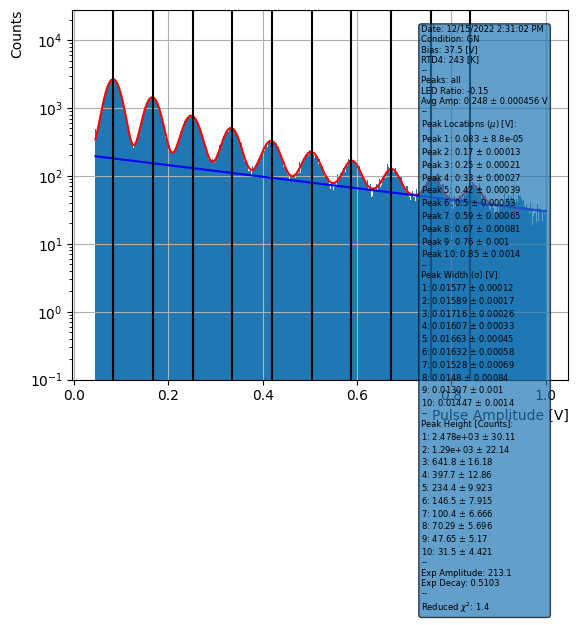

[0.084, 0.168, 0.252, 0.336, 0.42, 0.504, 0.588, 0.672, 0.756, 0.84]


In [9]:
for bias in biases:
    if bias <= 27:
        continue
    ult.histograms[bias].plot_peak_histogram()
    print(ult.histograms[bias].centers)

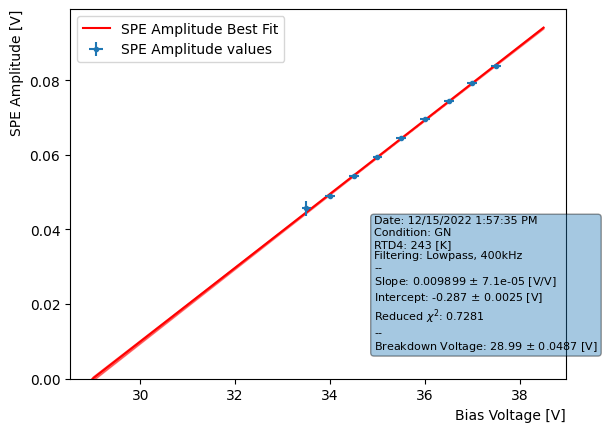

[0.04570323 0.06951433 0.07448751 0.04893122 0.06457163 0.07923803
 0.05446018 0.05933827 0.08388962]


In [10]:
ult.do_spe_data(invC=invC,invC_err=invCerr,biases=biases)
ult.spe_data.plot_spe(in_ov=False,absolute=False)
print(ult.spe_data.spe_vals)